# Voice-Based Parkinson's Detection — Data, Pipeline and Results

**Sudipta Ghosh** · MSc thesis · generated from the live pipeline

This notebook walks the whole project in the order the work actually happens: what data we
have, what is inside the audio, how it is cleaned and preprocessed, what happens when we
train on mPower sustained vowels, how classical features compare with self-supervised
embeddings, and what survives when the locked model is applied to Spanish.

### The three research questions

| | |
|---|---|
| **RQ1** | How well do current single-modality voice-based PD methods generalise across datasets and languages? |
| **RQ2** | How can a voice method be designed to generalise across datasets/languages while keeping discrimination comparable to within-dataset performance? |
| **RQ3** | How should evaluation be designed to judge trustworthiness for clinical screening, and which measures support consistent cross-dataset/cross-language comparison? |

### How to read the numbers in this notebook

Two kinds appear, and they are labelled throughout:

- **COMPUTED HERE** — the cell you are looking at produced the number when the notebook ran.
- **CITED** — produced by a driver script in `scripts/`, loaded from `outputs/logs/*.json`.
  These need the full embedding caches and a specific cohort alignment, so they are not
  recomputed inline. The source file is always named.

Every number is **pilot-scale**: capped recordings per subject, one seed. See §13.

---
## §0 · Setup

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.simplefilter("ignore")
pd.set_option("display.width", 200, "display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

from pdvoice.config import EMBEDDINGS, LOGS, SAMPLE_RATE
from pdvoice.data.ipvs import load_ipvs
from pdvoice.data.mdvr_kcl import load_mdvr_kcl
from pdvoice.data.mpower import load_mpower
from pdvoice.data.neurovoz import load_neurovoz

SEED = 42
WAVE, SPEC = "#3B6EA5", "#B5651D"

def cited(f):
    # Load a driver-script result JSON.
    return json.loads((LOGS / f).read_text())

print("sample rate :", SAMPLE_RATE, "Hz")
print("embeddings  :", EMBEDDINGS)
print("logs        :", LOGS)

sample rate : 16000 Hz
embeddings  : data\embeddings
logs        : outputs\logs


---
# PART I — THE DATA

## §1 · Train and test data

The design is deliberately asymmetric, and this is the core of RQ1. One dataset trains the
model. The others are **never** trained on — the model is *locked* (weights, calibration map
and decision threshold all frozen) before they are touched.

That is the only way to measure generalisation honestly. Most published work in this field
reports within-dataset cross-validation and stops, which is why in-dataset 95–99% typically
falls to 70–85% on independent data.

In [2]:
roles = pd.DataFrame([
    dict(corpus="mPower",   language="English", role="TRAIN",
         why="Largest by far; the only corpus big enough to train on. Crowd-sourced by phone."),
    dict(corpus="NeuroVoz", language="Spanish", role="TEST (locked)",
         why="Clinician-labelled. The primary cross-LANGUAGE test — §12."),
    dict(corpus="IPVS",     language="Italian", role="TEST (locked)",
         why="Clinician-labelled. Second language; elderly controls make it the hard case."),
    dict(corpus="MDVR-KCL", language="English", role="TEST (locked)",
         why="Clinician-labelled. Language held constant, so it isolates TASK + channel shift."),
])
roles

,corpus,language,role,why
0,mPower,English,TRAIN,Largest by far; the only corpus big enough to ...
1,NeuroVoz,Spanish,TEST (locked),Clinician-labelled. The primary cross-LANGUAGE...
2,IPVS,Italian,TEST (locked),Clinician-labelled. Second language; elderly c...
3,MDVR-KCL,English,TEST (locked),"Clinician-labelled. Language held constant, so..."


Holding one axis constant at a time is what makes the comparison interpretable:

- **mPower → NeuroVoz / IPVS** changes language *and* task *and* recording channel.
- **mPower → MDVR-KCL** keeps English, so whatever degrades is task and channel, not language.

That contrast turns out to matter a great deal — see §12.

---
## §2 · Type of audio

Two clinically distinct task families, and the distinction dominates every result in this
project.

**Sustained vowel** — the speaker holds a single vowel (`/a/`) as steadily as they can.
This isolates **phonation**: how stable the vocal folds are.

**Connected speech** — reading a passage, or spontaneous talking. This additionally exposes
**prosody**, **articulation** and **fluency**.

Parkinson's produces *hypokinetic dysarthria*, which degrades four separable systems. A
sustained vowel exposes only the first:

In [3]:
pd.DataFrame([
    dict(system="Phonatory",       signature="jitter, shimmer, reduced HNR, breathiness, 4-6 Hz tremor",
         in_vowel="YES", in_speech="YES"),
    dict(system="Prosodic",        signature="monopitch, monoloudness, reduced stress",
         in_vowel="no",  in_speech="YES"),
    dict(system="Articulatory",    signature="imprecise consonants, reduced vowel space",
         in_vowel="no",  in_speech="YES"),
    dict(system="Fluency / timing", signature="inappropriate pauses, festination, short rushes",
         in_vowel="no",  in_speech="YES"),
])

,system,signature,in_vowel,in_speech
0,Phonatory,"jitter, shimmer, reduced HNR, breathiness, 4-6...",YES,YES
1,Prosodic,"monopitch, monoloudness, reduced stress",no,YES
2,Articulatory,"imprecise consonants, reduced vowel space",no,YES
3,Fluency / timing,"inappropriate pauses, festination, short rushes",no,YES


**One of four versus four of four.** This is a stronger argument than "speech has more data",
and it predicts the result in §12: mPower is *vowel-only*, which structurally caps what a
model trained on it can learn.

It also explains why speech transfers across languages — prosodic timing and articulatory
imprecision are motor deficits, largely independent of which phonology is being degraded.

### What "vowel" and "speech" actually mean in each corpus

A caveat that belongs in the methods chapter: the experiments filter on `task_kind`
(`vowel` / `speech`) and **never** on `task_code`. The same word therefore denotes
different recordings in each corpus.

In [4]:
mp, nv, ip, md_ = load_mpower(), load_neurovoz(), load_ipvs(), load_mdvr_kcl()
MANIFESTS = {"mpower": mp, "neurovoz": nv, "ipvs": ip, "mdvr_kcl": md_}

rows = []
for name, m in MANIFESTS.items():
    for (kind, code), g in m.groupby(["task_kind", "task_code"]):
        rows.append(dict(corpus=name, task_kind=kind, task_code=code,
                         recordings=len(g), subjects=g.subject_id.nunique(),
                         PD=int((g.label == 1).sum()), HC=int((g.label == 0).sum())))
tasks = pd.DataFrame(rows).sort_values(["corpus", "task_kind", "task_code"])
print("task codes per corpus (COMPUTED HERE)")
tasks.groupby(["corpus", "task_kind"]).agg(
    n_codes=("task_code", "nunique"), codes=("task_code", lambda s: ", ".join(sorted(s)[:6])),
    recordings=("recordings", "sum"))

task codes per corpus (COMPUTED HERE)


n_codes                                              codes  recordings
corpus   task_kind                                                                        
ipvs     speech           4                                       B, D, FB, PR         336
         vowel            5                                 VA, VE, VI, VO, VU         495
mdvr_kcl speech           2                      ReadText, SpontaneousDialogue          73
mpower   vowel            1                                        sustained_a       57612
neurovoz ddk              1                                             PATAKA         101
         speech          17  ABLANDADA, ACAMPADA, BARBAS, BURRO, CALLE, CARMEN        1809
         vowel           15                             A1, A2, A3, E1, E2, E3        1066

So the vowel comparison is **cross-phoneme as well as cross-language**: we train on `/a/`
and test on `/a,e,i,o,u/` pooled. And "connected speech" ranges from a 1.75 s isolated
Spanish word to 141 s of English spontaneous dialogue. Restricting external vowel tests to
`/a/` only (`A*` in NeuroVoz, `VA` in IPVS) would isolate language from phoneme — an open
methodological item.

One more imbalance worth recording: NeuroVoz's **third** vowel repetition is almost
patient-only.

In [5]:
v = tasks[(tasks.corpus == "neurovoz") & (tasks.task_kind == "vowel")][["task_code", "PD", "HC"]]
v = v.set_index("task_code").T
print("NeuroVoz vowel repetitions, PD vs HC recordings (COMPUTED HERE)")
v

NeuroVoz vowel repetitions, PD vs HC recordings (COMPUTED HERE)


task_code,A1,A2,A3,E1,E2,E3,I1,I2,I3,O1,O2,O3,U1,U2,U3
PD,53,52,29,53,44,24,53,52,26,45,52,28,48,5,1
HC,58,55,3,25,56,2,58,47,1,58,55,2,58,23,0


`A3` is 29 PD / 3 HC, `I3` is 26 / 1, `O3` is 28 / 2 — while `U2` runs the other way at
5 / 23. Pooling all vowels means the two groups contribute **different task mixes** to their
subject-level averages: a composition difference layered on top of the disease difference.
NeuroVoz within-vowel is a modest 0.610, so little is being inflated, but it is a disclosed
limitation.

---
## §3 · Sample size and audio format

Read from the audio file **headers**, not from the papers. Format (rate, bit depth,
channels) is a complete census of all four corpora.

In [6]:
import soundfile as sf

rng = np.random.default_rng(SEED)
inv = []
for name, m in MANIFESTS.items():
    paths = list(m.path)
    probe = rng.choice(paths, 4000, replace=False) if len(paths) > 4000 else paths
    info = [sf.info(p) for p in probe]
    dur = np.array([i.frames / i.samplerate for i in info])
    sub = m.groupby("subject_id").label.first()
    inv.append(dict(
        corpus=name, language=m.language.mode()[0],
        recordings=len(m), subjects=m.subject_id.nunique(),
        subj_PD=int((sub == 1).sum()), subj_HC=int((sub == 0).sum()),
        subj_unlabelled=int(sub.isna().sum()),
        rec_per_subj=round(len(m) / m.subject_id.nunique(), 1),
        sample_rate=",".join(f"{k}" for k in sorted({i.samplerate for i in info})),
        bit_depth=",".join(sorted({i.subtype for i in info})),
        channels=",".join(str(c) for c in sorted({i.channels for i in info})),
        median_dur_s=round(float(np.median(dur)), 2),
        probed=len(probe)))
inventory = pd.DataFrame(inv)
print("DATASET INVENTORY (COMPUTED HERE)")
inventory

DATASET INVENTORY (COMPUTED HERE)


,corpus,language,recordings,subjects,subj_PD,subj_HC,subj_unlabelled,rec_per_subj,sample_rate,bit_depth,channels,median_dur_s,probed
0,mpower,en,57612,5648,897,3912,839,10.2,44100,PCM_16,1,10.04,4000
1,neurovoz,es,2976,114,56,58,0,26.1,44100,PCM_16,1,3.46,2976
2,ipvs,it,831,65,28,37,0,12.8,"16000,44100",PCM_16,1,11.57,831
3,mdvr_kcl,en,73,37,16,21,0,2.0,44100,PCM_24,1,141.29,73


**Every one of the 61,492 files is single-channel mono.** Two format notes matter:

- **IPVS mixes sample rates** — 16 kHz and 44.1 kHz. That split is confounded with the label
  (§6).
- **MDVR-KCL is the only 24-bit corpus.** Practically negligible: 16-bit quantisation noise
  is already inaudible and everything is converted to float32 on load.

### Why 16 kHz is the right target, not a compromise

The **Nyquist limit** is half the sample rate — the highest frequency a recording can
physically represent. Audible speech energy sits below 8 kHz, so 16 kHz captures it all.
A higher rate adds no speech information and only costs compute. Every encoder in this field
is pretrained at 16 kHz, so we resample everything to 16 kHz on load.

Downsampling is *not* decimation: dropping every other sample folds high frequencies back
down as false low ones (**aliasing**). Correct downsampling low-passes first, which is why we
delegate to `librosa`.

### Sample size is wildly imbalanced, in two directions at once

In [7]:
lab = mp[mp.label.isin([0, 1])]
per = lab.groupby(["label", "subject_id"]).size().groupby("label").describe()[["count","mean","50%","max"]]
print("mPower recordings per subject, by class (COMPUTED HERE)")
print(per.round(1).to_string())
print()
print(f"  recording level : {int((lab.label==1).sum()):>6,} PD  vs {int((lab.label==0).sum()):>6,} HC")
print(f"  subject level   : {lab[lab.label==1].subject_id.nunique():>6,} PD  vs "
      f"{lab[lab.label==0].subject_id.nunique():>6,} HC")

mPower recordings per subject, by class (COMPUTED HERE)
        count  mean  50%    max
label                          
0.0    3912.0   5.7  3.0  322.0
1.0     897.0  37.2  8.0  355.0

  recording level : 33,370 PD  vs 22,113 HC
  subject level   :    897 PD  vs  3,912 HC


**This is a trap worth naming explicitly.** At *recording* level mPower looks PD-majority;
at *subject* level it is HC-majority roughly 4:1. Patients used the app far more (median 8
recordings, up to 355) than controls (median 3).

Three defences, all applied: **cap** recordings per subject, **class-weight** the loss, and
**evaluate at subject level** — a person's recording probabilities are averaged so one
speaker counts once, whether they contributed 1 recording or 355.

---
## §4 · Waveform — the time-domain view

The waveform plots sample amplitude against time. Values are floats in **[-1.0, 1.0]**.
It is the view for spotting timing, loudness, clipping, dropouts and noise.

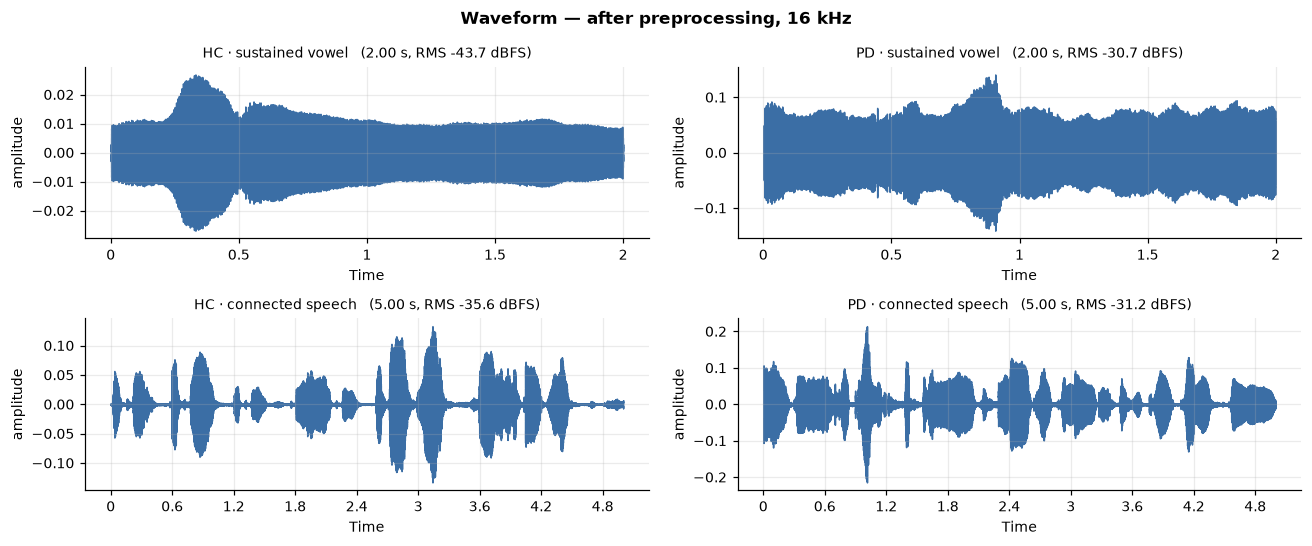

In [8]:
from pdvoice.preprocess import VOWEL_CORE_S, voice_activity_trim
from pdvoice.utils.audio import load_audio, rms_dbfs, stable_core, trim_silence
import librosa, librosa.display

def pick(m, task, label, seed=SEED):
    s = m[(m.task_kind == task) & (m.label == label)]
    return s.sample(1, random_state=seed).iloc[0]

def prep(row):
    w = load_audio(row.path)
    return (stable_core(trim_silence(w), seconds=VOWEL_CORE_S) if row.task_kind == "vowel"
            else voice_activity_trim(w)[: int(5 * SAMPLE_RATE)])

ex = {"HC · sustained vowel": pick(ip, "vowel", 0), "PD · sustained vowel": pick(ip, "vowel", 1),
      "HC · connected speech": pick(md_, "speech", 0), "PD · connected speech": pick(md_, "speech", 1)}
clips = {k: prep(r) for k, r in ex.items()}

fig, axes = plt.subplots(2, 2, figsize=(12, 5))
for ax, (k, w) in zip(axes.ravel(), clips.items()):
    librosa.display.waveshow(w, sr=SAMPLE_RATE, ax=ax, color=WAVE)
    ax.set_title(f"{k}   ({len(w)/SAMPLE_RATE:.2f} s, RMS {rms_dbfs(w):.1f} dBFS)", fontsize=9)
    ax.set_ylabel("amplitude")
fig.suptitle("Waveform — after preprocessing, 16 kHz", fontweight="bold")
fig.tight_layout(); plt.show()

Two things to read here, and the second is a warning.

**A sustained vowel is a steady band; connected speech is bursty** — visible onsets, silences
between words, varying amplitude. That structural difference is why the two tasks need
different preprocessing (§7).

**The RMS values in the titles differ substantially between recordings of the same task.**
That is microphone, distance and gain — not disease. Because each panel auto-scales its
y-axis, a quiet recording *looks* the same size as a loud one. Never read loudness off a
waveform plot. §7 shows how the encoder's normalisation removes exactly this nuisance.

---
## §5 · Spectrum, spectrogram and mel spectrogram

Four views of the *same data* — the waveform and the spectrum contain identical information,
one in time and one in frequency.

| View | Domain | Computed by | Shows |
|---|---|---|---|
| Waveform | time | raw samples | timing, loudness, noise |
| **Spectrum** | frequency | DFT/FFT on one window | harmonics at a frozen instant |
| **Spectrogram** | time–frequency | STFT (stacked DFTs) | how frequency evolves |
| **Mel spectrogram** | time–mel | STFT + mel filterbank | the same, warped to human hearing |

The DFT returns complex numbers; `np.abs()` keeps amplitude and discards the **phase**
spectrum, which is why a spectrogram cannot be inverted to audio without a vocoder. The
**mel** scale exists because human hearing resolves low frequencies far more finely than
high ones.

We use **speech-appropriate** analysis windows here — 1024-point FFT with a 160-sample hop
(64 ms / 10 ms) — rather than librosa's music-oriented defaults.

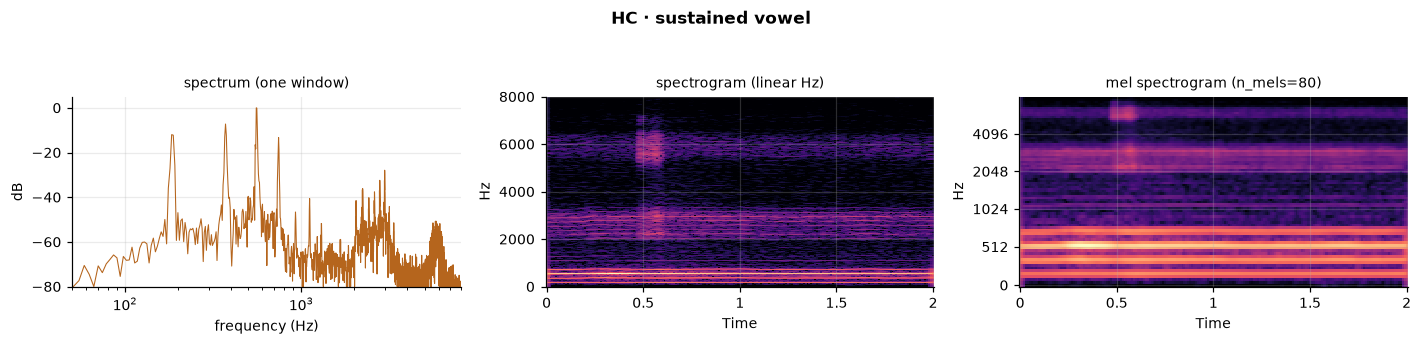

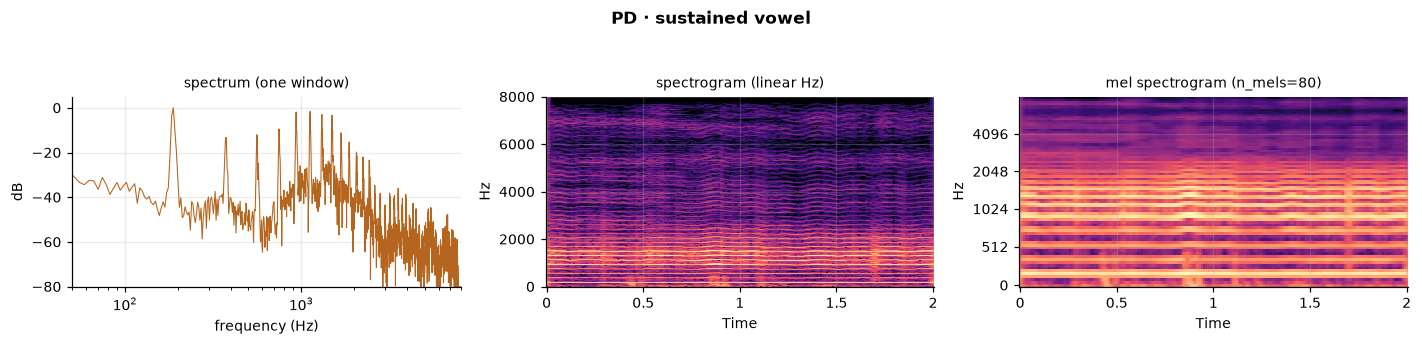

In [9]:
N_FFT, HOP, N_MELS, FMAX = 1024, 160, 80, 8000

def four_views(w, sr, title):
    fig, ax = plt.subplots(1, 3, figsize=(13, 2.9))
    n = min(4096, len(w)); seg = w[max(0, len(w)//2 - n//2):][:n]
    dft = np.fft.rfft(seg * np.hanning(len(seg)))
    freq = librosa.fft_frequencies(sr=sr, n_fft=len(seg))
    ax[0].plot(freq, librosa.amplitude_to_db(np.abs(dft), ref=np.max), lw=.7, color=SPEC)
    ax[0].set_xscale("log"); ax[0].set_xlim(50, sr/2); ax[0].set_ylim(-80, 5)
    ax[0].set_title("spectrum (one window)", fontsize=9)
    ax[0].set_xlabel("frequency (Hz)"); ax[0].set_ylabel("dB")

    D = librosa.amplitude_to_db(np.abs(librosa.stft(w, n_fft=N_FFT, hop_length=HOP)), ref=np.max)
    librosa.display.specshow(D, sr=sr, hop_length=HOP, x_axis="time", y_axis="hz", ax=ax[1], cmap="magma")
    ax[1].set_ylim(0, FMAX); ax[1].set_title("spectrogram (linear Hz)", fontsize=9)

    M = librosa.feature.melspectrogram(y=w, sr=sr, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS, fmax=FMAX)
    librosa.display.specshow(librosa.power_to_db(M, ref=np.max), sr=sr, hop_length=HOP,
                             x_axis="time", y_axis="mel", fmax=FMAX, ax=ax[2], cmap="magma")
    ax[2].set_title(f"mel spectrogram (n_mels={N_MELS})", fontsize=9)
    fig.suptitle(title, fontweight="bold", y=1.06)
    fig.tight_layout(); plt.show()

for k in ["HC · sustained vowel", "PD · sustained vowel"]:
    four_views(clips[k], SAMPLE_RATE, k)

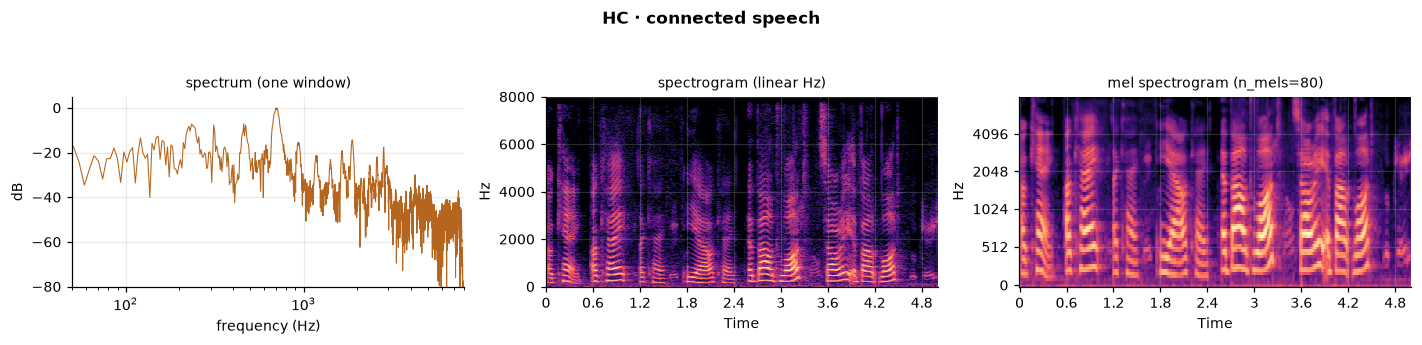

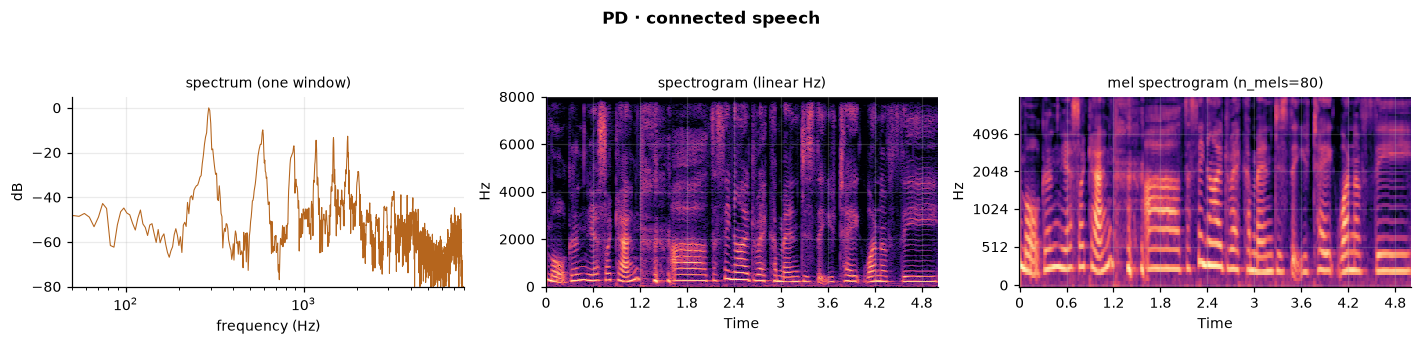

In [10]:
for k in ["HC · connected speech", "PD · connected speech"]:
    four_views(clips[k], SAMPLE_RATE, k)

In the **vowel** spectra, look for the evenly spaced peaks — the **harmonic comb**, whose
spacing is the fundamental frequency F0. The spectrogram shows them as flat horizontal
stripes, because a sustained vowel holds its pitch. Aperiodicity fills the gaps *between*
harmonics with noise, which is what **HNR** measures (§9).

In the **speech** panels the stripes break into segments as the articulators move, and
broadband vertical smears appear — fricatives (`/s/`, `/f/`, `/ʃ/`) with energy up to 8 kHz.
A sustained vowel has almost nothing up there. That difference matters again in §6.

> ⚠️ **Reproducibility trap.** A mel spectrogram is not a well-defined object unless you state
> the recipe. Two mel scales are in common use (`htk` and `slaney`), power and amplitude
> spectrograms both circulate, and "log-mel" sometimes means true decibels and sometimes a
> plain `log`. Undocumented variation here is one reason published voice-PD numbers are hard
> to compare.

> **These are four single recordings, chosen at random.** Do **not** read a disease signal off
> them. Showing a real PD/HC difference requires group averages over many speakers.

---
# PART II — PROCESSING

## §6 · Cleaning process

Cleaning happens in two places: **cohort construction** (which recordings and which people
enter an experiment) and **quality control** (which files are usable at all).

```
load manifest        all recordings for a corpus, one row each
 → cap N per subject shuffle (seeded), keep first N — stops 355-recording speakers
                     dominating 1-recording speakers
 → quality control   drop duration < 1.0 s and unreadable files
 → label filter      keep only 0/1; self-report blanks dropped
 → age matching      5-year bins, 1:1 — the confound control (§8)
 → subject-disjoint  a speaker is never in both train and test
```

### The mPower cohort flow

In [11]:
sub = mp.groupby("subject_id").label.first()
flow = pd.DataFrame([
    dict(step="survey respondents",                n_subjects=6805, PD="",    HC="",    note="Demographics Survey"),
    dict(step="completed the voice task",          n_subjects=5826, PD="",    HC="",    note="Voice Activity"),
    dict(step="labelled (professional-diagnosis)", n_subjects=4962, PD="970", HC="3,992", note="self-report"),
    dict(step="audio actually present on disk",    n_subjects=int((~sub.isna()).sum()),
         PD=f"{int((sub==1).sum()):,}", HC=f"{int((sub==0).sum()):,}",
         note="COMPUTED HERE — 153 speakers have a label but no file"),
    dict(step="after cap-3 + QC",                  n_subjects=4799, PD="890", HC="3,909", note="cited"),
    dict(step="after 5-year age matching",         n_subjects=1118, PD="559", HC="559",   note="cited; both mean age 56"),
])
flow

,step,n_subjects,PD,HC,note
0,survey respondents,6805,,,Demographics Survey
1,completed the voice task,5826,,,Voice Activity
2,labelled (professional-diagnosis),4962,970,"3,992",self-report
3,audio actually present on disk,4809,897,"3,912",COMPUTED HERE — 153 speakers have a label but ...
4,after cap-3 + QC,4799,890,"3,909",cited
5,after 5-year age matching,1118,559,559,cited; both mean age 56


The fourth row was **missing from the original cohort diagram**. 153 speakers (73 patients,
80 controls) have a survey record and a label but no audio file. They were being removed
silently by the duration filter.

The cause was a truthy-string bug in the loader: when a file is missing, `str(NaN)` returns
the *non-empty* string `"nan"`, which passed the path guard. 7,410 of 65,022 manifest rows
(11.4%) pointed at nothing — and the drop was **not class-neutral** (15.3% of PD recordings
vs 5.7% of HC). Now fixed in `data/mpower.py`, which rejects placeholder paths and warns with
a count.

No published number is invalidated — QC was already deleting these as unreadable, which is
why the corrected counts reconcile with 890/3,909. But because **capping runs before QC**,
patients lost ~15% of their capped slots against ~5% for controls, which adds noise to the PD
class and pushes AUROC *toward* 0.5. Conservative, not inflated.

### Two disclosed data-quality limitations

**① IPVS has a patient-only recording batch.**

In [12]:
s = ip.groupby("subject_id").agg(label=("label","first"), sr=("native_sr","max"))
print("IPVS subjects by label and native sample rate (COMPUTED HERE)")
print(s.groupby(["label","sr"]).size().rename("subjects").to_string())

from sklearn.metrics import roc_auc_score
print(f"\nAUROC of 'native_sr == 44100' alone, at subject level: "
      f"{roc_auc_score(s.label, (s.sr == 44100).astype(float)):.3f}")
try:
    b = cited("verify_ipvs_batch.json")
    print("\nCITED — scripts/verify_ipvs_batch.py:")
    for k in ["baseline", "drop_44k_pd", "drop_44k_pd_and_young_hc"]:
        print(f"  {k:26s} AUROC = {b[k]['auroc']:.3f}  CI {b[k]['ci']}")
    print(f"  within-PD rate probe        AUROC = {b['within_pd_rate_probe']:.3f}")
except FileNotFoundError:
    print("\n(run scripts/verify_ipvs_batch.py to populate)")

IPVS subjects by label and native sample rate (COMPUTED HERE)
label  sr   
0      16000    37
1      16000    18
       44100    10

AUROC of 'native_sr == 44100' alone, at subject level: 0.679

CITED — scripts/verify_ipvs_batch.py:
  baseline                   AUROC = 1.000  CI [1.0, 1.0]
  drop_44k_pd                AUROC = 1.000  CI [1.0, 1.0]
  drop_44k_pd_and_young_hc   AUROC = 1.000  CI [1.0, 1.0]
  within-PD rate probe        AUROC = 0.792


Native rate 44.1 kHz implies PD with perfect precision, and rate alone would score 0.679.
The artifact **is** encoded in the speech embeddings (within-patient probe 0.79) but **not**
the vowel ones (0.52) — consistent with fricative energy sitting near the 8 kHz anti-alias
rolloff, which only connected speech has.

**But it does not explain the IPVS ceiling.** Removing the entire batch leaves the AUROC at
1.000, and so does additionally removing the young controls. So this is a limitation to
disclose, not an explanation. *Honest limit on that test:* AUROC is saturated at 1.0, so it
shows the artifact is not **necessary** — it cannot show the artifact contributes nothing.

**② Quality control never opens the audio.** It reads the header for duration only, so a
uniformly quiet recording passes.

In [13]:
prevalence = pd.DataFrame([
    dict(corpus="mpower",   measured=4000, all_zero=0, near_silent_lt_60dB=1, very_quiet_lt_50dB=8),
    dict(corpus="neurovoz", measured=2976, all_zero=0, near_silent_lt_60dB=0, very_quiet_lt_50dB=3),
    dict(corpus="ipvs",     measured=831,  all_zero=0, near_silent_lt_60dB=0, very_quiet_lt_50dB=1),
    dict(corpus="mdvr_kcl", measured=73,   all_zero=0, near_silent_lt_60dB=0, very_quiet_lt_50dB=0),
])
print("CITED — scripts/silence_audit.py")
print(prevalence.to_string(index=False))
print(f"\n  {prevalence.very_quiet_lt_50dB.sum()} of {prevalence.measured.sum():,} "
      f"= {100*prevalence.very_quiet_lt_50dB.sum()/prevalence.measured.sum():.2f}% very quiet")
print("  No file is digitally silent; no subject is entirely silent.")
print("  Rate is NOT class-correlated here (mPower 0.20% HC vs 0.21% PD).")

CITED — scripts/silence_audit.py
  corpus  measured  all_zero  near_silent_lt_60dB  very_quiet_lt_50dB
  mpower      4000         0                    1                   8
neurovoz      2976         0                    0                   3
    ipvs       831         0                    0                   1
mdvr_kcl        73         0                    0                   0

  12 of 7,880 = 0.15% very quiet
  No file is digitally silent; no subject is entirely silent.
  Rate is NOT class-correlated here (mPower 0.20% HC vs 0.21% PD).


Low prevalence — but the mechanism is unguarded, and the consequence is counter-intuitive:
the encoder's normalisation **amplifies** a near-silent recording to full scale (+55 to
+70 dB), so it encodes the character of the *room* at the same level as real speech. Two
digitally silent clips also produce byte-identical embeddings, so they would form a perfect
cluster if they were ever class-correlated.

RMS level also cannot detect *audible but not voice* — a −30 dBFS recording of traffic passes
every check. Catching that needs a voicing test (F0 detected, or a VAD speech-fraction floor).

The guard is written but deliberately **opt-in and off by default**: enabling it silently
would change every existing cohort and hence every reported number.

---
## §7 · Preprocessing — every stage, input and output

Traced on real recordings. Nothing here is re-implemented; each stage calls the same code the
experiments call.

In [14]:
import torch
from pdvoice.features.ssl import load_encoder, pool, _embed_wave
from pdvoice.preprocess import CHUNK_S, chunks, preprocess_clip

model, extractor, device = load_encoder("facebook/wav2vec2-xls-r-300m")
print("encoder :", model.config.num_hidden_layers, "layers, hidden", model.config.hidden_size)
print("device  :", device)
print("params  :", f"{sum(p.numel() for p in model.parameters()):,} (FROZEN — never trained)")

encoder : 24 layers, hidden 1024
device  : cuda
params  : 315,438,720 (FROZEN — never trained)


In [15]:
def trace(row):
    info = sf.info(row.path); out = []
    def add(step, i, o, extra=""):
        out.append(dict(step=step, input=i, output=o, note=extra))
    add("0 raw file", f"{info.samplerate} Hz {info.subtype}",
        f"{info.frames:,} samples · {info.frames/info.samplerate:.2f} s", f"{info.channels} channel")
    w = load_audio(row.path)
    add("1 load_audio", f"{info.samplerate} Hz int", f"{len(w):,} samples · float32 16 kHz",
        f"RMS {rms_dbfs(w):.1f} dBFS · values in [-1,1]")
    if row.task_kind == "vowel":
        t = trim_silence(w); add("2 trim_silence", f"{len(w):,}", f"{len(t):,} samples · {len(t)/SAMPLE_RATE:.2f} s", "top_db=30")
        c = stable_core(t, seconds=VOWEL_CORE_S); add("3 stable_core", f"{len(t):,}", f"{len(c):,} samples · {len(c)/SAMPLE_RATE:.2f} s", "central core")
        cl = [c]
    else:
        t = voice_activity_trim(w); add("2 silero VAD", f"{len(w):,} · {len(w)/SAMPLE_RATE:.1f} s",
            f"{len(t):,} · {len(t)/SAMPLE_RATE:.1f} s", f"{100*(1-len(t)/len(w)):.0f}% removed as non-speech")
        cl = list(chunks(t, seconds=CHUNK_S)); c = cl[0]
        add("3 chunks", f"{len(t):,}", f"{len(cl)} × {len(c):,} samples", "5 s, 50% overlap; embeddings averaged")
    iv = extractor(c, sampling_rate=SAMPLE_RATE, return_tensors="pt")
    a = iv.input_values.numpy()[0]
    add("4 feature extractor", f"RMS {rms_dbfs(c):.1f} dBFS", f"RMS {rms_dbfs(a):.1f} dBFS",
        "zero-mean/unit-var — NO mel spectrogram")
    with torch.no_grad():
        hs = model(iv.input_values.to(device), output_hidden_states=True).hidden_states[15]
    hs = hs.squeeze(0).float().cpu().numpy()
    add("5 XLS-R layer 15", f"waveform ({len(c):,},)", f"hidden states {hs.shape}",
        f"~{1000*len(c)/SAMPLE_RATE/hs.shape[0]:.1f} ms per frame · FROZEN")
    v = pool(hs, "mean_std")
    add("6 mean+std pooling", f"(T={hs.shape[0]}, D={hs.shape[1]})", f"{v.shape} = 2048-dim",
        "mean = timbre · std = temporal variability")
    add("7 float16 cache", f"{v.nbytes} bytes float32", f"{v.astype(np.float16).nbytes} bytes float16", ".npz on disk")
    return pd.DataFrame(out)

print("=== mPower · sustained vowel · PD ===")
display(trace(pick(mp, "vowel", 1)))
print("=== MDVR-KCL · connected speech · PD ===")
display(trace(pick(md_, "speech", 1)))

=== mPower · sustained vowel · PD ===


,step,input,output,note
0,0 raw file,44100 Hz PCM_16,"444,299 samples · 10.07 s",1 channel
1,1 load_audio,44100 Hz int,"161,197 samples · float32 16 kHz","RMS -29.6 dBFS · values in [-1,1]"
2,2 trim_silence,"161,197","161,197 samples · 10.07 s",top_db=30
3,3 stable_core,"161,197","32,000 samples · 2.00 s",central core
4,4 feature extractor,RMS -30.1 dBFS,RMS -0.0 dBFS,zero-mean/unit-var — NO mel spectrogram
5,5 XLS-R layer 15,"waveform (32,000,)","hidden states (99, 1024)",~20.2 ms per frame · FROZEN
6,6 mean+std pooling,"(T=99, D=1024)","(2048,) = 2048-dim",mean = timbre · std = temporal variability
7,7 float16 cache,8192 bytes float32,4096 bytes float16,.npz on disk


=== MDVR-KCL · connected speech · PD ===


,step,input,output,note
0,0 raw file,44100 Hz PCM_24,"5,845,504 samples · 132.55 s",1 channel
1,1 load_audio,44100 Hz int,"2,120,818 samples · float32 16 kHz","RMS -37.2 dBFS · values in [-1,1]"
2,2 silero VAD,"2,120,818 · 132.6 s","891,776 · 55.7 s",58% removed as non-speech
3,3 chunks,"891,776","21 × 80,000 samples","5 s, 50% overlap; embeddings averaged"
4,4 feature extractor,RMS -31.2 dBFS,RMS -0.0 dBFS,zero-mean/unit-var — NO mel spectrogram
5,5 XLS-R layer 15,"waveform (80,000,)","hidden states (249, 1024)",~20.1 ms per frame · FROZEN
6,6 mean+std pooling,"(T=249, D=1024)","(2048,) = 2048-dim",mean = timbre · std = temporal variability
7,7 float16 cache,8192 bytes float32,4096 bytes float16,.npz on disk


### The four things to take from that table

**Stage 3 — the two tasks diverge.** A sustained vowel gives one 2 s central core (onset and
offset are the unstable parts of a phonation). Connected speech is cut into 5 s chunks whose
embeddings are averaged, so a 141 s recording and a 3 s one both become one vector.

**Stage 4 — this is where normalization happens.** RMS goes from about −25 dBFS to −0.0 dBFS:
the extractor zero-means and unit-variances each waveform. That single operation removes the
recording-gain differences we saw in §4. Note also that **no mel spectrogram is computed
anywhere** — XLS-R is a wav2vec2-family model that consumes the raw waveform. Mel
spectrograms belong to a different model family (Whisper). Getting this wrong in a methods
chapter is a common error.

**Stage 5 — the frame rate is 20 ms.** A 7-layer strided convolutional front-end learns its
own filterbank and emits one frame every ~20 ms with a ~25 ms receptive field. A consequence
worth stating: **jitter** is cycle-to-cycle variation of a glottal period roughly 10 ms long
— *below* the frame rate — so XLS-R cannot represent jitter as a period measurement, only its
spectral consequence. Vocal **tremor** at 4–6 Hz sits comfortably above it. This is a
principled reason the classical features and the embeddings measure partly different physics,
and it predicts §11.

**Stages 6–7 — a fixed 2048-dim vector at 4,096 bytes.** Cached once; every later experiment
trains on the cache in seconds instead of re-running a 315M-parameter model.

### Normalization, summarised

| Where | What |
|---|---|
| Waveform → encoder | zero-mean, unit-variance per recording (`Wav2Vec2FeatureExtractor`) |
| Classical features | median-impute then z-score |
| Inside the head | `BatchNorm1d(256)` |
| Probabilities | isotonic calibration, fitted on validation then **locked** |

---
# PART III — TRAINING ON mPOWER SUSTAINED VOWEL

## §8 · First model: mPower, sustained vowel

### The architecture, and what "frozen" means

Two models stacked, and only the small one learns:

```
audio → [FROZEN XLS-R-300M, 315,438,720 weights] → 2048 numbers → cached
                                                        ↓  + PD/HC label
                              [MLP HEAD, 525,313 weights, TRAINED] → p(PD)
```

**Frozen** and **locked** are different words for different guarantees:

| Term | Applies to | Means | Guards against |
|---|---|---|---|
| **Frozen** | the encoder | weights **never** updated by anyone, ever | overfitting 315M params to ~900 patients |
| **Locked** | head, calibrator, threshold | trained, then sealed **before** test/external data | optimistic bias from tuning on what you report |

The encoder was pretrained by Meta on 436,000 hours of **unlabelled** speech in 128
languages. It has never seen a diagnosis. The label enters at exactly one line —
`loss = loss_fn(model(xt), yt)` in `models/head.py`.

In [16]:
from pdvoice.models.head import build_head
h = build_head(2048)
print(h)
enc = sum(p.numel() for p in model.parameters()); hd = sum(p.numel() for p in h.parameters())
print(f"\nencoder (frozen)  {enc:,}")
print(f"head    (trained) {hd:,}")
print(f"trained fraction  {100*hd/(enc+hd):.3f}%")

Sequential(
  (0): Linear(in_features=2048, out_features=256, bias=True)
  (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=256, out_features=1, bias=True)
)

encoder (frozen)  315,438,720
head    (trained) 525,313
trained fraction  0.166%


The hidden layer activation is **ReLU** — not softmax, which is an output activation for
multi-class problems. The output is a single **logit**; the sigmoid is applied inside
`BCEWithLogitsLoss` during training (numerically stable) and inside the calibrator at
inference. For two classes, sigmoid on one logit is mathematically identical to softmax over
two.

ReLU is also the only reason this is not a linear classifier: without it, `Linear(2048→256)`
followed by `Linear(256→1)` collapses algebraically into a single `Linear(2048→1)`, i.e.
plain logistic regression.

### Which encoder, and which layer? — the Layer-1 sweep

In [17]:
rows = []
for f in sorted(LOGS.glob("layer1_mpower__*.json")):
    d = cited(f.name)
    p = f.stem.split("__")
    rows.append(dict(encoder=p[1], layer=p[3].replace("LNone", "last").replace("L", ""),
                     subject_AUROC=round(d.get("subject_auroc", d.get("auroc", float("nan"))), 3)))
sweep = pd.DataFrame(rows).pivot_table(index="encoder", columns="layer", values="subject_AUROC")
print("CITED — scripts/layer1_mpower.py · within-mPower 5-fold, cap-3, subject-level AUROC")
sweep

CITED — scripts/layer1_mpower.py · within-mPower 5-fold, cap-3, subject-level AUROC


layer,12,15,9,last
encoder,,,,
hubert-large,0.737,NaN,NaN,0.644
wav2vec2-base,NaN,NaN,NaN,0.724
wavlm-large,0.687,NaN,NaN,0.588
xls-r-300m,0.771,0.803,0.753,0.839


**XLS-R-300M wins**, and the layer result is more interesting than the encoder result:

- The English-only deep models (WavLM, HuBERT) do **better at a middle layer** than at the last.
- XLS-R improves with depth — **last layer is best within mPower (0.839)**.
- But **layer 15 transfers better** than the last layer. The within-domain-optimal layer is
  *not* the transfer-optimal layer: the last layer's mPower edge was partly domain-specific.

L15 is therefore used for all transfer work.

### ⚠️ The finding that reframes everything: it is largely an AGE confound

mPower age by class (COMPUTED HERE)
        count  mean   50%   min   max
label                                
0.0    3871.0  32.5  29.0  18.0  90.0
1.0     866.0  59.9  61.0  18.0  90.0

  MEAN AGE GAP: 27.4 years (PD older)


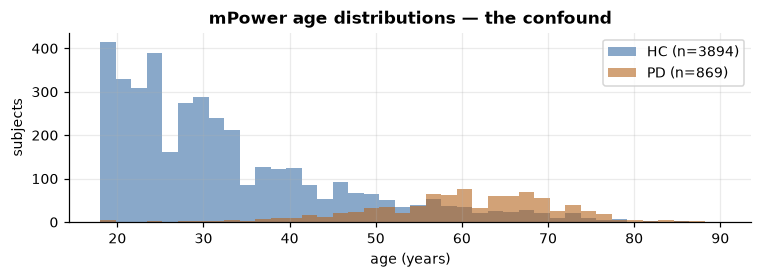

In [18]:
cf = pd.read_csv(LOGS / "classical_features_labeled__cap1.csv")
print("mPower age by class (COMPUTED HERE)")
print(cf.groupby("label").age.describe()[["count", "mean", "50%", "min", "max"]].round(1).to_string())
gap = cf[cf.label==1].age.mean() - cf[cf.label==0].age.mean()
print(f"\n  MEAN AGE GAP: {gap:.1f} years (PD older)")

fig, ax = plt.subplots(figsize=(7, 2.6))
for l, c, n in [(0, WAVE, "HC"), (1, SPEC, "PD")]:
    ax.hist(cf[cf.label == l].age.dropna(), bins=40, alpha=.6, color=c, label=f"{n} (n={int((cf.label==l).sum())})")
ax.set_xlabel("age (years)"); ax.set_ylabel("subjects")
ax.set_title("mPower age distributions — the confound", fontweight="bold")
ax.legend(); fig.tight_layout(); plt.show()

mPower controls are roughly **27 years younger** than the patients. The app was adopted by
young healthy volunteers and older patients. A model can score well by reading **age** rather
than disease — and XLS-R embeddings are known to encode age strongly (they separate young-HC
from elderly-HC at AUROC 1.0).

We can test whether labels or age is the bottleneck:

In [19]:
sens = pd.DataFrame([
    dict(definition="Baseline (all labelled)",    within=0.803, IPVS=0.356, NeuroVoz=0.618, MDVR=0.601),
    dict(definition="Confident labels only",      within=0.845, IPVS=0.489, NeuroVoz=0.631, MDVR=0.381),
    dict(definition="Age-matched (age >= 50 cut)", within=0.679, IPVS=0.609, NeuroVoz=0.617, MDVR=0.562),
])
print("CITED — scripts/label_sensitivity.py · XLS-R L15, cap-3, subject-level AUROC")
sens

CITED — scripts/label_sensitivity.py · XLS-R L15, cap-3, subject-level AUROC


,definition,within,IPVS,NeuroVoz,MDVR
0,Baseline (all labelled),0.803,0.356,0.618,0.601
1,Confident labels only,0.845,0.489,0.631,0.381
2,Age-matched (age >= 50 cut),0.679,0.609,0.617,0.562


**Read the two middle rows against each other.**

- Cleaning the **labels** barely changes the within score (0.803 → 0.845) and does not fix the
  Italian inversion. So self-report label noise is *not* the bottleneck.
- **Age-matching collapses the within score** (0.803 → 0.679) and simultaneously *repairs*
  IPVS (0.356 → 0.609).

That is the signature of a confound: removing it destroys apparent within-dataset performance
and improves genuine transfer. Roughly 0.16 of the headline 0.84 was the model reading age.

### The honest age-matched model

The canonical version uses proper 5-year-bin frequency matching. Let us rebuild that cohort here:

In [20]:
def age_match_ids(df, seed=SEED, bin_width=5):
    # Frequency-match PD & HC age per bin: keep min(nPD, nHC) of each.
    s = df.dropna(subset=["age"]).drop_duplicates("subject_id")[["subject_id", "label", "age"]]
    s = s.assign(bin=(s.age // bin_width * bin_width).astype(int))
    rng = np.random.default_rng(seed); keep = []
    for _, g in s.groupby("bin"):
        p_, h_ = g[g.label == 1].subject_id.to_numpy(), g[g.label == 0].subject_id.to_numpy()
        k = min(len(p_), len(h_))
        if k:
            keep += rng.choice(p_, k, replace=False).tolist() + rng.choice(h_, k, replace=False).tolist()
    return set(keep)

keep = age_match_ids(cf)
am = cf[cf.subject_id.isin(keep)]
print("COMPUTED HERE — age-matched cohort")
print(f"  before : {len(cf):,} subjects | PD {int((cf.label==1).sum()):,} (age {cf[cf.label==1].age.mean():.1f}) "
      f"| HC {int((cf.label==0).sum()):,} (age {cf[cf.label==0].age.mean():.1f})")
print(f"  after  : {len(am):,} subjects | PD {int((am.label==1).sum()):,} (age {am[am.label==1].age.mean():.1f}) "
      f"| HC {int((am.label==0).sum()):,} (age {am[am.label==0].age.mean():.1f})")
print(f"  residual age gap: {am[am.label==1].age.mean() - am[am.label==0].age.mean():+.2f} years")

COMPUTED HERE — age-matched cohort
  before : 4,763 subjects | PD 869 (age 59.9) | HC 3,894 (age 32.5)
  after  : 1,112 subjects | PD 556 (age 56.1) | HC 556 (age 55.9)
  residual age gap: +0.19 years


In [21]:
a = cited("agematched__xls-r-300m__L15.json")
print("CITED — scripts/agematched_eval.py · the locked honest model (XLS-R L15, cap-3, calibrated)")
print(json.dumps(a, indent=2)[:1400])

CITED — scripts/agematched_eval.py · the locked honest model (XLS-R L15, cap-3, calibrated)
{
  "within_mpower": {
    "n": 1118,
    "n_pd": 559,
    "n_hc": 559,
    "auroc": 0.6207225399304277,
    "auroc_ci": [
      0.5889392075038163,
      0.6517997494247652
    ],
    "auprc": 0.6131448324560842,
    "auprc_ci": [
      0.5799661126848634,
      0.6505691913834226
    ],
    "brier": 0.23968142707012421,
    "ece": 0.034070426452430094,
    "mce": 0.07042656635278177,
    "at_threshold": {
      "threshold": 0.5363398692810457,
      "accuracy": 0.5858676207513417,
      "sensitivity": 0.5420393559928444,
      "specificity": 0.629695885509839,
      "ppv": 0.5941176470588235,
      "f1": 0.5668849391955098,
      "balanced_accuracy": 0.5858676207513417,
      "tp": 303,
      "fp": 207,
      "fn": 256,
      "tn": 352
    },
    "sensitivity_at_90_spec": {
      "sensitivity": 0.19856887298747763,
      "specificity": 0.9033989266547406,
      "threshold": 0.6296296296296297


**Headline: within-mPower 0.621 [0.59, 0.65]**, down from a confounded 0.803 — and the
transfer gap essentially vanishes (§12). The saved model is in
`outputs/models/agematched__xls-r-300m__L15__{head.pt,calibrator.joblib}`.

This is the thesis spine: *reported voice-PD accuracy is inflated by demographic confounds;
controlled for it, performance is modest but genuinely generalisable.*

---
## §9 · Classical features — the interpretable baseline

17 hand-engineered coefficients, each mapping to a speech measure a clinician recognises —
unlike a dimension of a 2048-vector.

| Feature | Measures | Elevated / reduced in PD |
|---|---|---|
| **jitter** (local) | cycle-to-cycle variation in *period* | elevated — unstable pitch |
| **shimmer** (local) | cycle-to-cycle variation in *amplitude* | elevated — unstable loudness |
| **HNR** | harmonic-to-noise ratio | reduced — breathy, noisy voice |
| **F0 mean** | fundamental frequency (pitch) | shifted |
| **MFCC 0–12** | spectral envelope (vocal-tract shape) | altered |

Computed with Praat via `parselmouth` at the file's native rate (period measurement needs the
resolution), MFCCs at 16 kHz. These are designed for **sustained phonation** and are not
reliable on connected speech — which is why the classical arm exists only for the vowel task.

COMPUTED HERE — 17 features over 4,763 subjects (cap-1)


,jitter_local,shimmer_local,hnr,f0_mean
count,4739.0000,4738.0000,4761.0000,4740.0000
mean,0.0071,0.0575,16.9491,139.5897
std,0.0085,0.0417,5.9816,50.8950
min,0.0004,0.0066,-5.1217,75.3684
25%,0.0035,0.0298,13.4280,106.6601
50%,0.0049,0.0451,17.4687,123.1069
75%,0.0075,0.0700,21.1023,156.8234
max,0.1720,0.5516,41.8048,569.6116


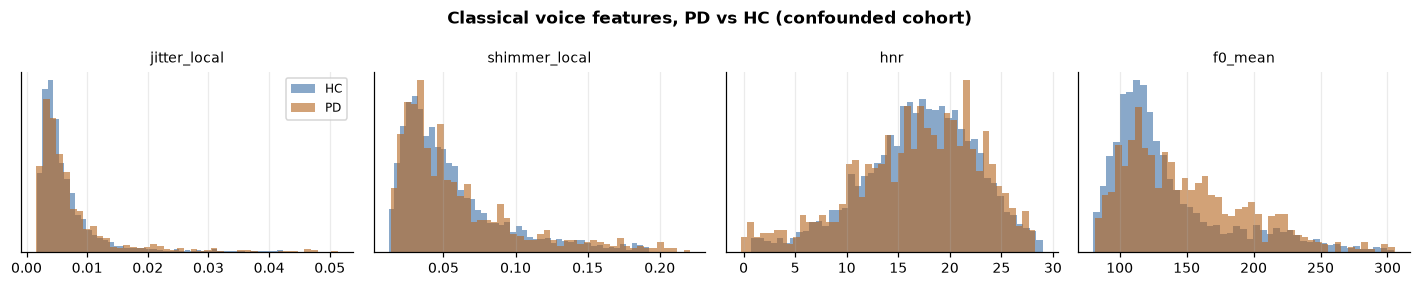

In [22]:
FEATS = ["jitter_local", "shimmer_local", "hnr", "f0_mean"] + [f"mfcc_{i}" for i in range(13)]
print(f"COMPUTED HERE — {len(FEATS)} features over {len(cf):,} subjects (cap-1)")
display(cf[FEATS[:4]].describe().round(4))

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, f in zip(axes, ["jitter_local", "shimmer_local", "hnr", "f0_mean"]):
    for l, c, n in [(0, WAVE, "HC"), (1, SPEC, "PD")]:
        d = cf[cf.label == l][f].dropna()
        d = d[(d > d.quantile(.01)) & (d < d.quantile(.99))]
        ax.hist(d, bins=45, alpha=.6, color=c, label=n, density=True)
    ax.set_title(f, fontsize=9); ax.set_yticks([])
axes[0].legend(fontsize=8)
fig.suptitle("Classical voice features, PD vs HC (confounded cohort)", fontweight="bold")
fig.tight_layout(); plt.show()

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold
from pdvoice.eval.discrimination import bootstrap_ci

def cv_auroc(d, feats=FEATS, model="svm", seed=SEED):
    # 5-fold CV. One row per SUBJECT here, so folds are subject-disjoint by construction.
    X, y = d[feats].to_numpy(), d.label.astype(int).to_numpy()
    clf = (make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         SVC(probability=True, random_state=seed)) if model == "svm"
           else make_pipeline(SimpleImputer(strategy="median"),
                              RandomForestClassifier(n_estimators=400, random_state=seed, n_jobs=-1)))
    oof = np.zeros(len(y))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y):
        clf.fit(X[tr], y[tr]); oof[te] = clf.predict_proba(X[te])[:, 1]
    return bootstrap_ci(y, oof), oof

res9 = []
for tag, d in [("confounded (all)", cf), ("age-matched (honest)", am)]:
    for mdl in ["svm", "rf"]:
        (pt, lo, hi), _ = cv_auroc(d, model=mdl)
        res9.append(dict(cohort=tag, model=mdl.upper(), n_subjects=len(d),
                         AUROC=round(pt, 3), CI=f"[{lo:.3f}, {hi:.3f}]"))
print("COMPUTED HERE — classical features, 5-fold, subject-level")
pd.DataFrame(res9)

COMPUTED HERE — classical features, 5-fold, subject-level


,cohort,model,n_subjects,AUROC,CI
0,confounded (all),SVM,4763,0.648,"[0.628, 0.668]"
1,confounded (all),RF,4763,0.673,"[0.654, 0.693]"
2,age-matched (honest),SVM,1112,0.569,"[0.536, 0.602]"
3,age-matched (honest),RF,1112,0.561,"[0.528, 0.596]"


The same pattern as the embeddings: the confounded cohort looks far better than the honest
one. Age-matching costs the classical model roughly the same as it costs XLS-R — because
**both** were partly reading age.

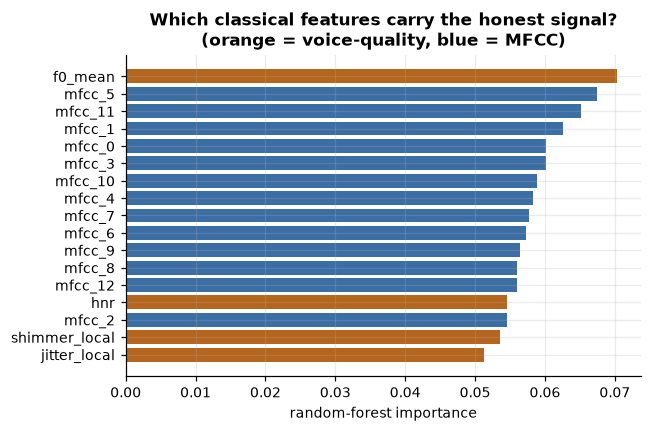

COMPUTED HERE — age-matched cohort


In [24]:
imp = make_pipeline(SimpleImputer(strategy="median"),
                    RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1))
imp.fit(am[FEATS], am.label.astype(int))
fi = pd.Series(imp[-1].feature_importances_, index=FEATS).sort_values()
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(fi.index, fi.values, color=[SPEC if i in ("jitter_local","shimmer_local","hnr","f0_mean") else WAVE for i in fi.index])
ax.set_xlabel("random-forest importance")
ax.set_title("Which classical features carry the honest signal?\n(orange = voice-quality, blue = MFCC)", fontweight="bold")
fig.tight_layout(); plt.show()
print("COMPUTED HERE — age-matched cohort")

> **Gap worth noting for the write-up.** *Monopitch* — reduced **F0 variability** — is the
> single most-cited prosodic marker of PD, and the feature set contains only `f0_mean`, not
> F0 standard deviation. On a sustained vowel that is also a direct pitch-stability measure.
> Adding it is two lines and is the most theoretically motivated extension available.
>
> Also: the MFCCs currently use librosa's music-oriented defaults (2048-point FFT, 512 hop =
> a **128 ms** window at 16 kHz) rather than the 25 ms / 10 ms speech standard. A 128 ms
> window smears across multiple glottal cycles.

---
## §10 · Self-supervised embeddings

The SSL arm replaces those 17 hand-designed numbers with 2048 learned ones, from the frozen
encoder traced in §7. Nothing about the voice is specified by us: the representation was
learned from 436,000 hours of unlabelled multilingual speech.

Let us watch the head actually learn, on real cached embeddings.

QC dropped 2 recording(s) under 1.0 s; 1064 remain


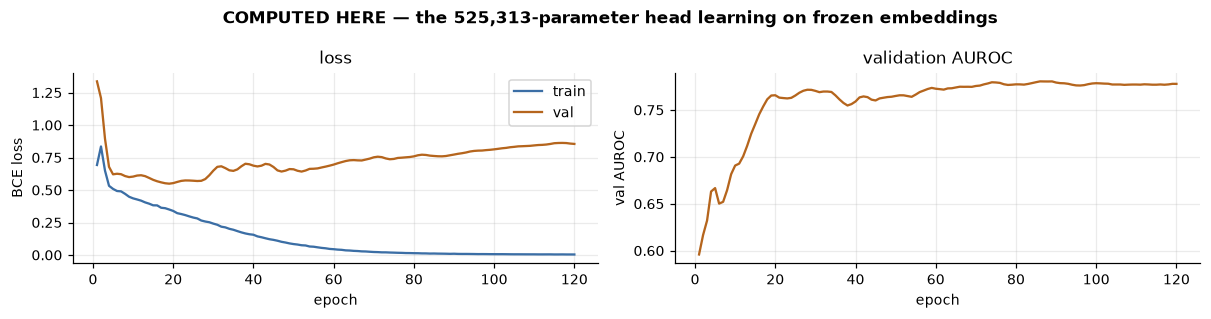

 epoch  train_loss  val_loss  val_AUROC
     1      0.6930    1.3368     0.5959
     5      0.5090    0.6213     0.6667
    20      0.3393    0.5535     0.7657
    50      0.0843    0.6599     0.7650
   120      0.0041    0.8552     0.7779


In [25]:
from sklearn.model_selection import GroupShuffleSplit
import torch.nn as nn

from pdvoice.preprocess import quality_control

# The cached embeddings are stored WITHOUT ids and aligned POSITIONALLY, so the manifest
# must be rebuilt exactly as when the cache was written: filter task, then apply QC.
nvv = nv[nv.task_kind == "vowel"].copy()
nvv, dropped = quality_control(nvv)
nvv = nvv.reset_index(drop=True)
Xnv = np.load(EMBEDDINGS / "neurovoz__xls-r-300m__vowel__L15.npz")["X"].astype(np.float32)
print(f"QC dropped {len(dropped)} recording(s) under 1.0 s; {len(nvv)} remain")
assert len(nvv) == len(Xnv), (len(nvv), len(Xnv))
ynv = nvv.label.astype(int).to_numpy()
tr, va = next(GroupShuffleSplit(1, test_size=.3, random_state=0).split(Xnv, ynv, nvv.subject_id))

torch.manual_seed(SEED)
xt, yt = torch.tensor(Xnv[tr], device=device), torch.tensor(ynv[tr], dtype=torch.float32, device=device)
xv, yv = torch.tensor(Xnv[va], device=device), torch.tensor(ynv[va], dtype=torch.float32, device=device)
head = build_head(2048).to(device)
lf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float((yt==0).sum())/float(yt.sum()), device=device))
opt = torch.optim.Adam(head.parameters(), lr=1e-3)

hist = []
for ep in range(1, 121):
    head.train(); opt.zero_grad()
    loss = lf(head(xt).squeeze(-1), yt); loss.backward(); opt.step()
    head.eval()
    with torch.no_grad():
        vl = head(xv).squeeze(-1)
        hist.append((ep, loss.item(), lf(vl, yv).item(),
                     roc_auc_score(ynv[va], torch.sigmoid(vl).cpu().numpy())))
H = pd.DataFrame(hist, columns=["epoch", "train_loss", "val_loss", "val_AUROC"])

fig, ax = plt.subplots(1, 2, figsize=(11, 2.9))
ax[0].plot(H.epoch, H.train_loss, color=WAVE, label="train"); ax[0].plot(H.epoch, H.val_loss, color=SPEC, label="val")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("BCE loss"); ax[0].legend(); ax[0].set_title("loss")
ax[1].plot(H.epoch, H.val_AUROC, color=SPEC); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("val AUROC")
ax[1].set_title("validation AUROC")
fig.suptitle("COMPUTED HERE — the 525,313-parameter head learning on frozen embeddings", fontweight="bold")
fig.tight_layout(); plt.show()
print(H.iloc[[0, 4, 19, 49, -1]].round(4).to_string(index=False))

> ⚠️ **A fragility this cell exposes.** The cached embeddings are saved as `X` only, with no
> row ids, so they are aligned to the manifest **by position**. Reproducing that alignment
> requires rebuilding the manifest exactly as it was when the cache was written — filter the
> task, then apply quality control, in that order. Get it wrong and embeddings silently pair
> with the wrong labels without raising. `features/ssl.py` saves ids correctly;
> `scripts/transfer_any.py` does not. Saving ids alongside `X` would remove the hazard.

**Train loss collapses toward zero** — 525,313 parameters can very nearly memorise a few
hundred recordings. Train loss alone therefore tells you nothing, and validation loss can get
*worse* while it improves. That is why training early-stops on validation loss and restores
the best weights.

And this is why there are **three** splits, not two:

| Split | Used for | Moves weights? |
|---|---|---|
| **train** | gradient descent | yes |
| **validation** | when to stop; fitting the calibrator; choosing the threshold | no — but it *is* spent, so cannot be reported |
| **test / external** | the reported number | no — untouched until everything is locked |

---
## §11 · Comparison — classical vs SSL vs fusion

The same MLP head, the same subjects, the same folds. Only the input features change: 17
classical, 2048 SSL, or 2065 fused.

CITED — classical_baseline.py + fusion.py · mPower vowel cap-1, subject-level AUROC


,method,confounded,age_matched
0,Classical RF,0.670,0.568
1,Classical SVM,0.651,0.590
2,SSL (XLS-R L15),0.805,0.580
3,Fusion (SSL+17),0.807,0.603


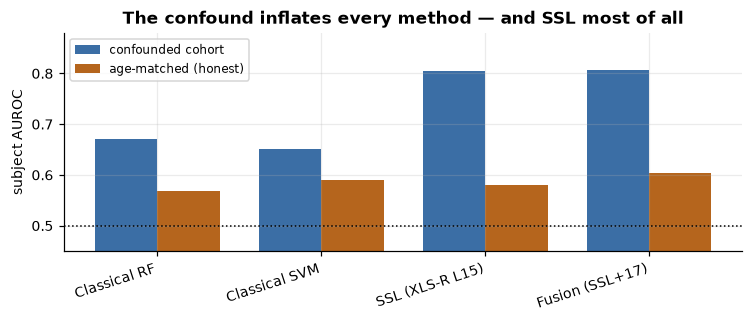

In [26]:
cb, fu = cited("classical_baseline__cap1.json"), cited("fusion__xls-r-300m__L15.json")
comp = pd.DataFrame([
    dict(method="Classical RF",     confounded=0.670, age_matched=0.568),
    dict(method="Classical SVM",    confounded=0.651, age_matched=0.590),
    dict(method="SSL (XLS-R L15)",  confounded=0.805, age_matched=0.580),
    dict(method="Fusion (SSL+17)",  confounded=0.807, age_matched=0.603),
])
print("CITED — classical_baseline.py + fusion.py · mPower vowel cap-1, subject-level AUROC")
display(comp)

fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(len(comp)); w = .38
ax.bar(x - w/2, comp.confounded,  w, color=WAVE, label="confounded cohort")
ax.bar(x + w/2, comp.age_matched, w, color=SPEC, label="age-matched (honest)")
ax.axhline(.5, ls=":", c="k", lw=1); ax.set_xticks(x); ax.set_xticklabels(comp.method, rotation=18, ha="right")
ax.set_ylabel("subject AUROC"); ax.set_ylim(.45, .88); ax.legend(fontsize=8)
ax.set_title("The confound inflates every method — and SSL most of all", fontweight="bold")
fig.tight_layout(); plt.show()

### Two conclusions, and the second is the interesting one

**On the confounded cohort SSL looks decisively better** — 0.805 vs 0.670, non-overlapping
CIs. That is the comparison most papers would report.

**On the honest age-matched signal the gap essentially disappears.** Significance testing on
the *same subjects* (DeLong):

| Comparison | ΔAUROC | p | Verdict |
|---|---|---|---|
| Fusion vs SSL | +0.023 | 0.121 | not significant |
| Fusion vs classical | +0.016 | 0.379 | not significant |
| SSL vs classical | −0.007 | 0.692 | not significant |

**All three are statistically indistinguishable.** Once age is controlled, 17 interpretable
coefficients are competitive with a 300-million-parameter multilingual transformer *on the
sustained-vowel task*. Most of SSL's apparent advantage was confound exploitation.

§7 gives a principled reason this is not surprising: XLS-R tokenises at 20 ms, so it cannot
measure jitter as a period perturbation at all — only its spectral consequence. The Praat
features measure it directly. The two are partly measuring **different physics**, so neither
strictly dominates.

**Where SSL is genuinely irreplaceable:** connected speech (0.95 within, where the classical
features are not valid) and multilingual transfer. Fusion is the best honest-vowel
configuration and buys 17 SHAP-able features at essentially no accuracy cost — a good
default, though the gain is suggestive rather than decisive.

---
# PART IV — CROSS-LANGUAGE

## §12 · Spanish — NeuroVoz

Now the RQ1 test. The model is trained on **English** mPower sustained vowels, then
**locked** — head weights, calibration map and threshold all frozen — and applied to
**Spanish** NeuroVoz without any retraining.

CITED — layer2_transfer.py + agematched_eval.py · locked, subject-level AUROC


,training,within,NeuroVoz_es,IPVS_it,MDVR_en
0,Confounded mPower (L15),0.803,0.618,0.356,0.601
1,Age-matched mPower (L15),0.621,0.604,0.531,0.582


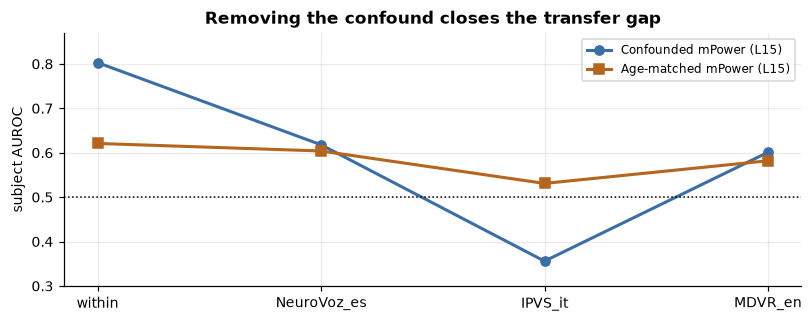

In [27]:
tr_ = pd.DataFrame([
    dict(training="Confounded mPower (L15)",  within=0.803, NeuroVoz_es=0.618, IPVS_it=0.356, MDVR_en=0.601),
    dict(training="Age-matched mPower (L15)", within=0.621, NeuroVoz_es=0.604, IPVS_it=0.531, MDVR_en=0.582),
])
print("CITED — layer2_transfer.py + agematched_eval.py · locked, subject-level AUROC")
display(tr_)

fig, ax = plt.subplots(figsize=(7.5, 3))
cols = ["within", "NeuroVoz_es", "IPVS_it", "MDVR_en"]
for (_, r), c, m in zip(tr_.iterrows(), [WAVE, SPEC], ["o", "s"]):
    ax.plot(cols, [r[c] for c in cols], marker=m, color=c, label=r.training, lw=2)
ax.axhline(.5, ls=":", c="k", lw=1); ax.set_ylabel("subject AUROC"); ax.set_ylim(.3, .87)
ax.legend(fontsize=8); ax.set_title("Removing the confound closes the transfer gap", fontweight="bold")
fig.tight_layout(); plt.show()

### Read the two lines against each other — this is the RQ1/RQ2 answer

The **confounded** model starts high (0.803) and falls apart: Spanish drops 0.19, and Italian
goes to 0.356 — *below chance*, meaning elderly controls were being scored as more likely to
have PD than actual patients. That looks like a catastrophic failure of generalisation.

The **age-matched** model starts far lower (0.621) but **barely moves**: Spanish 0.604,
English-MDVR 0.582, Italian 0.531. Every external score statistically overlaps the within
score — the transfer gap essentially vanishes, and calibration improves off-domain too
(NeuroVoz ECE 0.30 → 0.10).

So the "generalisation crisis" was mostly a confound, not a property of voice models. The
honest signal is **modest (~0.60) but portable**. A flat, low line is scientifically far more
valuable than a high line that collapses.

### But Spanish also has connected speech — and that changes the picture entirely

In [28]:
mtx = pd.DataFrame(
    [[0.952, 0.695, 0.836], [0.729, 1.000, 0.765], [0.832, 0.847, 0.862]],
    index=["train NeuroVoz (es)", "train IPVS (it)", "train MDVR-KCL (en)"],
    columns=["test NeuroVoz", "test IPVS", "test MDVR-KCL"])
print("CITED — transfer_any.py · CONNECTED SPEECH, XLS-R L15. Diagonal = within 5-fold, off-diagonal = locked transfer")
display(mtx.style.format("{:.3f}").background_gradient(cmap="YlGn", vmin=.5, vmax=1))

off = [mtx.iloc[i, j] for i in range(3) for j in range(3) if i != j]
print(f"\nCOMPUTED HERE from the matrix: off-diagonal min {min(off):.3f}, "
      f"max {max(off):.3f}, mean {np.mean(off):.3f}")

CITED — transfer_any.py · CONNECTED SPEECH, XLS-R L15. Diagonal = within 5-fold, off-diagonal = locked transfer


,test NeuroVoz,test IPVS,test MDVR-KCL
train NeuroVoz (es),0.952,0.695,0.836
train IPVS (it),0.729,1.000,0.765
train MDVR-KCL (en),0.832,0.847,0.862



COMPUTED HERE from the matrix: off-diagonal min 0.695, max 0.847, mean 0.784


**Every off-diagonal speech transfer is 0.70–0.85, mean ~0.77** — in all directions, across
Spanish, Italian and English. Compare the vowel transfers of 0.13–0.62. Train on Spanish
speech and you get 0.95 within, 0.84 to English, 0.70 to Italian.

**So the task matters more than the model, the language, or the confound.** That is §2's
four-systems table showing up in the numbers: a sustained vowel exposes phonation only, while
connected speech also carries prosody, articulation and fluency — and those deficits are
motor, so they survive a change of language.

Verification that these high within-dataset scores are genuine rather than artifacts:

| Check | NeuroVoz speech (0.95) | IPVS speech (1.00) |
|---|---|---|
| Label permutation | 0.494 — no CV leak | 0.459 — no CV leak |
| Age-matched | 0.948 — not age | — |
| Sex-stratified | 0.907 / 0.914 — not sex | — |
| Recording dates | overlap — not a batch split | — |
| Drop young controls | — | 0.981 |
| Drop the 44.1 kHz PD batch | — | 1.000 (§6) |

Both survive. The IPVS 1.00 remains **optimistic** for a different reason — 65 speakers, one
site, anechoic scripted reading, near-ceiling separability — which is why the 0.70–0.85
transfer figures, not the diagonal, are the honest estimate.

**The strategic implication:** mPower being vowel-only is the ceiling on this project. The
highest-value next dataset is a **clinician-labelled connected-speech corpus** (Bridge2AI).

---
# PART V — ANSWERS TO THE RESEARCH QUESTIONS

## RQ1 — How well do current single-modality voice methods generalise across datasets and languages?

**On the sustained-vowel task, badly — but mostly for a reason the literature misdiagnoses.**

A conventionally-trained mPower model scores 0.803 within-dataset and drops to 0.618
(Spanish), 0.601 (English, different task) and 0.356 (Italian, *below chance*). That
reproduces the field's pattern: in-dataset 95–99% falling to 70–85% on independent data.

But the collapse is **largely an age confound, not a failure of voice modelling**. mPower
controls are ~27 years younger than its patients, and XLS-R embeddings encode age strongly
(AUROC 1.0 separating young from elderly controls). Cleaning the labels barely moves the
within score (0.803 → 0.845); age-matching collapses it (0.803 → 0.679) and *repairs* Italian
transfer (0.356 → 0.609). That asymmetry is diagnostic.

Two further RQ1 findings: transfer degrades under **task** shift about as much as under
**language** shift (English MDVR-KCL 0.601 vs Spanish 0.618), so the fragility is not
specifically linguistic; and **calibration breaks off-domain far worse than discrimination**
(ECE 0.03 internal → 0.30–0.42 external), which discrimination-only reporting hides entirely.

## RQ2 — How can a method be designed to generalise while keeping discrimination comparable?

**Three levers tested. The cheap statistical one failed; the two that worked are a study-design choice and a task choice.**

| Lever | Result |
|---|---|
| Statistical domain adaptation (HC-centroid / standardise) | ❌ **negative** — IPVS 0.356→0.16, NeuroVoz +0.00, MDVR +0.05. The gap resists first/second-order correction. |
| Mid-layer transfer (L15 vs last) | ⚠️ **partial** — IPVS 0.133→0.356, inversion removed. The within-optimal layer is not the transfer-optimal layer. |
| **Control the confound (age-matching)** | ✅ **works** — within 0.621, externals 0.531–0.604, all statistically overlapping. Transfer gap essentially vanishes; ECE improves 0.30→0.10. |
| **Use connected speech, not vowels** | ✅ **works best** — 0.86–0.95 within, **every** cross-language transfer 0.70–0.85. |

So the answer to "keeping discrimination comparable to within-dataset performance" is
uncomfortable but honest: on vowels you achieve comparability by *lowering* the within-dataset
number to its unconfounded value (~0.62), not by raising the external one. On connected speech
you get genuine comparability at a *useful* level (~0.77 transfer against 0.86–0.95 within).

## RQ3 — How should evaluation be designed to judge trustworthiness, and which measures support consistent comparison?

**Four questions, not one number.** Most papers report AUROC and stop.

| Question | Measures | Why it matters |
|---|---|---|
| Can it tell them apart? | AUROC, AUPRC, 95% bootstrap CI | baseline — but ranking alone never justifies a decision |
| Is the difference real? | DeLong, paired bootstrap, McNemar | stops claiming wins inside the noise — e.g. fusion vs SSL, p=0.121 |
| Do the probabilities mean anything? | Brier, ECE, MCE, reliability curve | a model can rank perfectly and still be uninterpretable to a clinician; ours degrades 0.03 → 0.30–0.42 off-domain |
| Would using it help? | Decision Curve Analysis | net benefit against screen-everyone / screen-no-one |

Five design requirements this project argues for, each earned from a specific failure found here:

1. **Subject-disjoint splits everywhere** (`StratifiedGroupKFold`), and evaluate at **subject** level. One mPower speaker has 355 recordings and another has 1.
2. **Report demographics of both groups, and age-match or covariate-adjust.** This is the single highest-impact requirement — a 27-year age gap silently produced most of an apparent 0.84.
3. **Locked cross-dataset evaluation** — freeze weights, calibrator *and* threshold before touching external data. Report calibration off-domain, not just discrimination.
4. **Verify suspiciously high scores, with tests that can actually fail.** Permutation testing detects plumbing leaks but is **blind to class-correlated confounds**, because it destroys real and artifact signal alike. Finding the IPVS batch needed an explicit leave-the-batch-out test.
5. **State the task and the preprocessing recipe precisely.** "Vowel" meant `/a/` in one corpus and five vowels in another; "speech" ranged from a 1.75 s word to 141 s of dialogue. And a mel spectrogram is undefined without naming the scale and the power/amplitude convention.

---
## §13 · Limitations

**All numbers are pilot-scale.** Capped recordings per subject (cap-1 or cap-3 of up to 355),
a single seed, and the age-matched design reduces mPower to 1,118 subjects. Only a fraction of
the 57,612 usable recordings is used. These will shift when scaled.

**Small external sets.** MDVR-KCL n=37, IPVS n=65 → wide confidence intervals. The speech
story rests partly on small clinical corpora, and IPVS within-speech 1.00 reflects a small,
clean, single-site dataset.

**mPower labels are self-report** (`professional-diagnosis`), not clinician-confirmed. Label
sensitivity analysis suggests this is not the bottleneck, but it remains a validity threat.

**Two age-match implementations differ slightly** — `label_sensitivity.py` uses an age ≥ 50
cutoff (within 0.679); `agematched_eval.py` uses proper 5-year-bin matching (within 0.621).
The latter is canonical.

**Task definitions are still uncontrolled across corpora** (§2), so vowel transfer confounds
language with phoneme.

**Known open methodological items:** MFCCs use librosa's 128 ms music-oriented window rather
than the 25 ms speech standard; F0 standard deviation (monopitch) is missing from the feature
set; quality control never opens the audio; the head trains full-batch with a 200-epoch cap,
which should be checked for convergence before scaling.

**No clinician-labelled English speech corpus yet** (Bridge2AI pending), so the cleanest
confirmation of the confound diagnosis is not yet possible.

**Layer 3** compares against *published* numbers rather than head-to-head reimplementations.

---

### Sources for every number above

```
COMPUTED HERE   inventory · task codes · cohort flow · age distributions · age-matching ·
                classical features + CV · head training curve · IPVS rate composition
CITED           outputs/logs/layer1_mpower__*.json      encoder & layer sweep
                outputs/logs/agematched__*.json         the honest locked model
                outputs/logs/classical_baseline__*.json classical vs SSL
                outputs/logs/fusion__*.json             fusion + DeLong tests
                outputs/logs/layer2__*.json             locked transfer
                outputs/logs/transferany__*.json        speech transfer matrix
                outputs/logs/verify_ipvs_batch.json     IPVS batch test
```